<a href="https://colab.research.google.com/github/shanchepngen-ux/ML-For-Engineering/blob/main/Week6_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WEEK6 ASSIGNMENT

We will use the following approach:
| Component                             | Purpose                                                                  |
| ------------------------------------- | ------------------------------------------------------------------------ |
| Satellite images                      | Provide the features used for clustering.                                |
| Spectral bands                        | Help describe surface and vegetation characteristics.                    |
| Elevation and slope bands, if present | Provide terrain-related information.                                     |
| Corresponding masks                   | Help us evaluate the landslide content of each cluster after clustering. |
| K-Means                               | Groups images with similar extracted characteristics.                    |
| PCA scatter plot                      | Displays the clusters in two dimensions.                                 |

Our clustering unit will be an entire image tile. We will calculate the mean and standard deviation of each image band, producing a feature vector for every image. This lets us cluster the 100 images without treating every individual pixel as an independent observation.

We will not use the masks to construct the clusters. Instead, we will use them afterward to investigate whether the groups differ in their proportion of landslide-labelled pixels. This helps us assess whether the clusters reveal potentially useful patterns.







In [5]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Dataset directories
image_dir = "/content/Landslide4Sense/images/train"
mask_dir = "/content/Landslide4Sense/annotations/train"

# Only attempt to open if the file exists
target_image = os.path.join(image_dir, "image_1.h5")
if os.path.exists(target_image):
    # Inspect the structure of the first image file
    with h5py.File(target_image, "r") as f:
        print("\nImage keys:", list(f.keys()))
        for key in f.keys():
            print(key, f[key].shape)

    # Inspect the matching mask
    with h5py.File(os.path.join(mask_dir, "mask_1.h5"), "r") as f:
        print("\nMask keys:", list(f.keys()))
        for key in f.keys():
            print(key, f[key].shape)
else:
    print(f"\nCould not find target file: {target_image}. Please verify download progress.")


Image keys: ['img']
img (128, 128, 14)

Mask keys: ['mask']
mask (128, 128)


In [4]:
from huggingface_hub import hf_hub_download
import os

repo_id = "ibm-nasa-geospatial/Landslide4sense"
local_dir = "/content/Landslide4Sense"

os.makedirs(local_dir, exist_ok=True)

print("Downloading 100 training images and their matching masks...")
# Download 100 training images and their matching masks
for i in range(1, 101):
    hf_hub_download(
        repo_id=repo_id,
        repo_type="dataset",
        filename=f"images/train/image_{i}.h5",
        local_dir=local_dir
    )
    hf_hub_download(
        repo_id=repo_id,
        repo_type="dataset",
        filename=f"annotations/train/mask_{i}.h5",
        local_dir=local_dir
    )

print("Download complete!")

images/train/image_1.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

images/train/image_1.h5: downloading bytes:           |  0.00B            

annotations/train/mask_1.h5: reconstructing file:   0%|          |  0.00B / 18.4kB            

annotations/train/mask_1.h5: downloading bytes:           |  0.00B            

images/train/image_2.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

...

images/train/image_100.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

images/train/image_100.h5: downloading bytes:           |  0.00B            

annotations/train/mask_100.h5: reconstructing file:   0%|          |  0.00B / 18.4kB            

annotations/train/mask_100.h5: downloading bytes:           |  0.00B            

Download complete!


In [6]:
image_features = []
landslide_fractions = []
image_names = []

for i in range(1, 101):

    image_path = os.path.join(image_dir, f"image_{i}.h5")
    mask_path = os.path.join(mask_dir, f"mask_{i}.h5")

    with h5py.File(image_path, "r") as f:
        image = f["img"][:]

    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:]

    # Ensure the image has a height, width, and channel dimension
    if image.ndim != 3:
        print(f"Skipping image {i}: unexpected shape {image.shape}")
        continue

    # Calculate mean and standard deviation for each image band
    features = []

    for band in range(image.shape[-1]):
        band_data = image[:, :, band]
        valid = np.isfinite(band_data)

        if valid.any():
            features.extend([
                np.mean(band_data[valid]),
                np.std(band_data[valid])
            ])
        else:
            features.extend([np.nan, np.nan])

    image_features.append(features)
    image_names.append(i)

    # Record mask coverage for later interpretation, not clustering
    valid_mask = np.isfinite(mask)

    if valid_mask.any():
        landslide_fractions.append(
            np.mean(mask[valid_mask] > 0)
        )
    else:
        landslide_fractions.append(np.nan)

# Create the feature table
feature_data = pd.DataFrame(image_features)
feature_data.index = image_names

print("Feature table shape:", feature_data.shape)
print(feature_data.head())

Feature table shape: (100, 28)
         0         1         2         3         4         5         6   \
1  1.167813  0.062042  1.225767  0.145064  1.337893  0.206467  1.469855   
2  1.170766  0.043539  1.235026  0.111382  1.357398  0.169932  1.532278   
3  1.106512  0.034672  1.127345  0.074881  1.186842  0.131254  1.218725   
4  1.148895  0.094602  1.218094  0.199339  1.354027  0.282877  1.516577   
5  1.085025  0.045437  1.111456  0.099849  1.181873  0.167142  1.243542   

         7         8         9   ...        18        19        20        21  \
1  0.394412  1.509508  0.262562  ...  1.487058  0.112854  1.554240  0.366187   
2  0.365452  1.546270  0.221677  ...  1.498769  0.103305  1.686941  0.298700   
3  0.237594  1.273738  0.219425  ...  1.413691  0.104303  1.261729  0.323407   
4  0.542941  1.547269  0.386612  ...  1.565107  0.160757  1.668290  0.467700   
5  0.306497  1.269540  0.262975  ...  1.444849  0.121224  1.307239  0.359665   

         22        23        24      

In [7]:
from sklearn.impute import SimpleImputer

# Remove columns containing only missing values
feature_data = feature_data.dropna(axis=1, how="all")

# Replace infinite values with missing values
feature_data = feature_data.replace(
    [np.inf, -np.inf], np.nan
)

# Impute missing feature values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(feature_data)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Prepared data shape:", X_scaled.shape)

Prepared data shape: (100, 28)


In [8]:
k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Display the evaluation results
evaluation = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

print(evaluation.round(4))

   Number of Clusters    Inertia  Silhouette Score
0                   2  1978.2827            0.2716
1                   3  1522.7604            0.2920
2                   4  1348.4596            0.2802
3                   5  1210.6378            0.2044
4                   6  1089.1436            0.2029
5                   7   987.5471            0.2171
6                   8   893.3681            0.2127


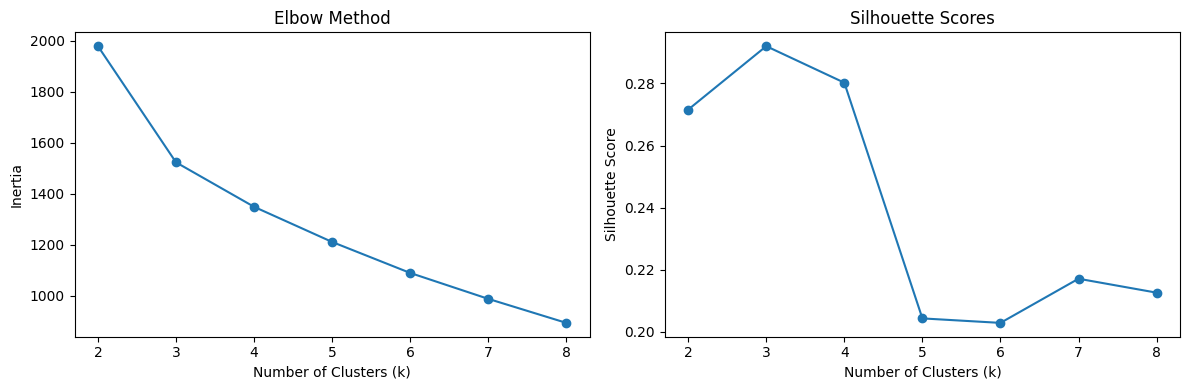

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow plot
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

# Silhouette plot
axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [10]:
# Select the best silhouette score among k = 2 to 8
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Selected number of clusters:", best_k)

# Fit the final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Create a results table
cluster_results = pd.DataFrame({
    "Image": image_names,
    "Cluster": cluster_labels,
    "Landslide_Fraction": landslide_fractions
})

print(cluster_results.head())

Selected number of clusters: 3
   Image  Cluster  Landslide_Fraction
0      1        1            0.024719
1      2        1            0.057190
2      3        1            0.000000
3      4        1            0.012878
4      5        1            0.016174


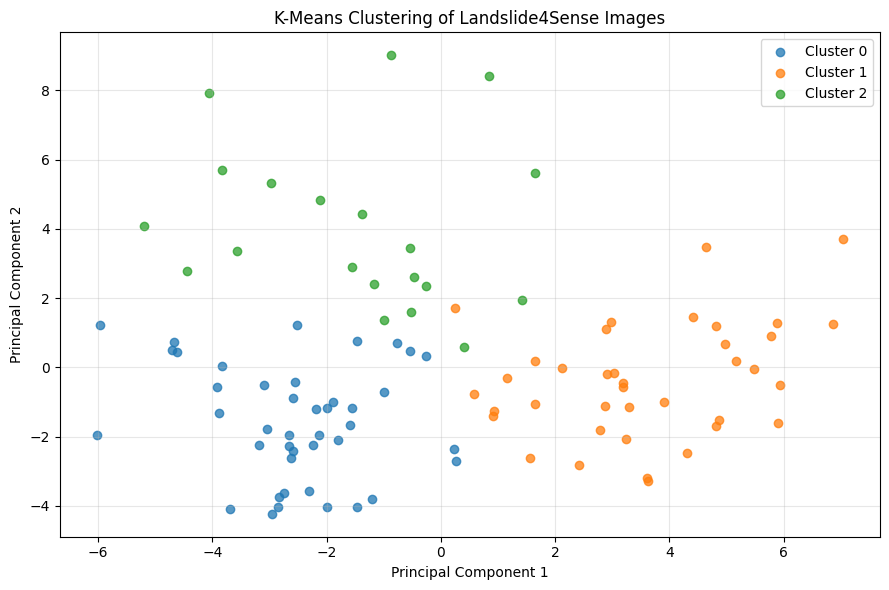

Variance explained by the two PCA components: 65.17 %


In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

for cluster in sorted(np.unique(cluster_labels)):

    selected = cluster_labels == cluster

    plt.scatter(
        X_pca[selected, 0],
        X_pca[selected, 1],
        label=f"Cluster {cluster}",
        alpha=0.75
    )

plt.title("K-Means Clustering of Landslide4Sense Images")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [13]:
cluster_summary = cluster_results.groupby("Cluster").agg(
    Number_of_Images=("Image", "count"),
    Mean_Landslide_Fraction=("Landslide_Fraction", "mean"),
    Median_Landslide_Fraction=("Landslide_Fraction", "median")
).round(4)

cluster_summary["Mean_Landslide_Percent"] = (
    cluster_summary["Mean_Landslide_Fraction"] * 100
).round(2)

print(cluster_summary)

         Number_of_Images  Mean_Landslide_Fraction  Median_Landslide_Fraction  \
Cluster                                                                         
0                      42                   0.0126                     0.0007   
1                      38                   0.0130                     0.0027   
2                      20                   0.0335                     0.0188   

         Mean_Landslide_Percent  
Cluster                          
0                          1.26  
1                          1.30  
2                          3.35  


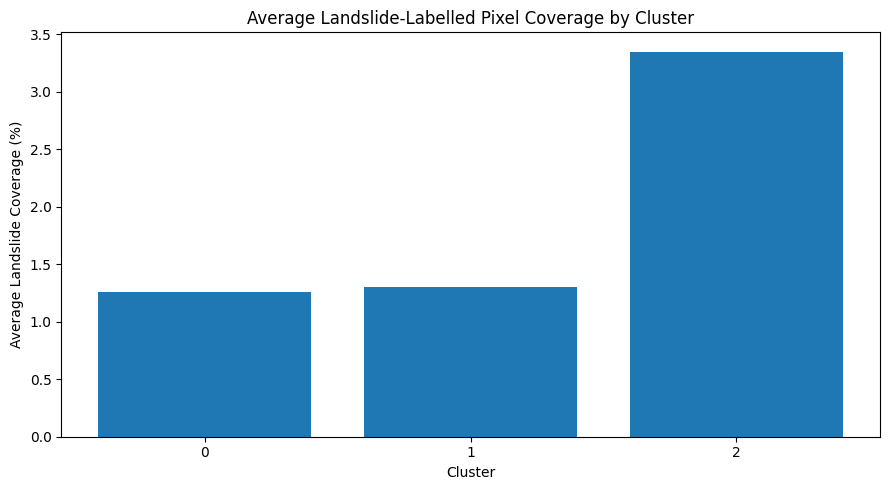

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    cluster_summary.index.astype(str),
    cluster_summary["Mean_Landslide_Percent"]
)

plt.title("Average Landslide-Labelled Pixel Coverage by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Landslide Coverage (%)")

plt.tight_layout()
plt.show()

### Discussion

K-Means clustering was applied to the Landslide4Sense dataset, producing three clusters containing 42, 38, and 20 images, respectively. The average landslide-mask coverage was 1.26% for Cluster 0, 1.30% for Cluster 1, and 3.35% for Cluster 2. Cluster 2 therefore had the highest average landslide coverage, while Clusters 0 and 1 showed relatively similar means. The median coverage was also highest in Cluster 2, suggesting that its higher average was not solely caused by a few extreme observations.

These findings indicate that the clustering model identified groups of satellite images with different distributions of landslide-labelled pixels. Cluster 2 may represent a group of images with more extensive landslide areas, while Clusters 0 and 1 generally contain less landslide-labelled area. However, since clustering was based on image-band statistics rather than the masks, these differences are exploratory and do not establish causation or directly measure landslide susceptibility. Further validation using labelled data and relevant environmental variables would be necessary to develop a predictive model.
